# PearlRoute Vision

PearlNet, a custom CNN trained from scratch. All logic is imported from the `pearlroute` package.

## 1. Setup
I import the tools I need and load my three config files (data, model, training).
The real code lives in the `pearlroute` package, so this notebook stays short and just *uses* it.
`SEED` makes random choices (like which sample images I show) the same every run.

In [1]:
import json
import os

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"  # hide TensorFlow's low-level info/warning messages

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf

tf.get_logger().setLevel("ERROR")  # hide TensorFlow's Python-side notices (e.g. "no GPU on Windows")

from pearlroute.config import load_data_config, load_model_config, load_train_config
from pearlroute.data.loaders import list_images, load_class_weights, load_datasets
from pearlroute.preprocessing.stats import compute_channel_stats, load_stats, save_stats
from pearlroute.preprocessing.transforms import read_and_resize

data_cfg, model_cfg, train_cfg = load_data_config(), load_model_config(), load_train_config()
CLASSES = data_cfg.class_names
SEED = data_cfg.seed

# Chart style: light background, quiet grid, no top/right borders.
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#52514e",
    "axes.labelcolor": "#0b0b0b", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e4e3dd", "grid.linewidth": 0.8, "axes.axisbelow": True, "font.size": 10,
})
SPLIT_COLOURS = {"train": "#2a78d6", "val": "#eb6834", "test": "#1baf7a"}
print("classes:", CLASSES)
print("image size:", model_cfg.image_size, "| batch size:", train_cfg.batch_size)

classes: ['cultural_heritage', 'gorilla_primate_trekking', 'mountain_hiking', 'waterfalls', 'whitewater_rafting', 'wildlife_safari']
image size: 160 | batch size: 32


## 2. How many images do I have?
`counts.json` is written by the cleaning and splitting scripts. **raw** is what I downloaded,
**clean** is what survived the quality checks (duplicates, black-and-white photos, tiny images).
The split table shows how the clean images were shared out; demo and retrain images are kept aside.

In [2]:
counts = json.loads(data_cfg.paths.counts_json.read_text())
cleaning = pd.DataFrame({"raw": counts["cleaning"]["raw"], "clean": counts["cleaning"]["clean"]})
cleaning["dropped"] = cleaning["raw"] - cleaning["clean"]
display(cleaning)

split_table = pd.DataFrame(counts["split"]["per_class"]).T[["train", "val", "test", "retrain", "demo"]]
display(split_table)
print("dropped by reason:", counts["cleaning"]["dropped_by_reason"])

,raw,clean,dropped
cultural_heritage,3300,3284,16
gorilla_primate_trekking,3256,2342,914
mountain_hiking,3300,3098,202
waterfalls,3300,3294,6
whitewater_rafting,3190,3187,3
wildlife_safari,3300,3279,21


,train,val,test,retrain,demo
cultural_heritage,2288,491,491,10,2
gorilla_primate_trekking,1617,350,349,10,2
mountain_hiking,2151,463,463,10,2
waterfalls,2268,492,492,10,2
whitewater_rafting,2198,477,476,10,1
wildlife_safari,2282,490,490,10,1


dropped by reason: {'manual exclude': 1154, 'near-duplicate': 5, 'grayscale': 3}


## 3. Chart: images per class in each split
Each bar is one class, cut into train (blue), val (orange) and test (aqua); the number is the total.
All classes should be roughly the same length, and every bar should be about 70 / 15 / 15.
If one class were much shorter, the model would see it less and probably predict it worse.

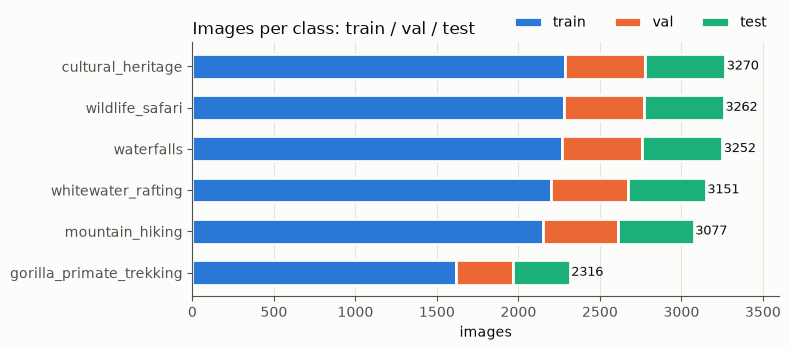

In [3]:
order = split_table.sort_values("train").index          # shortest at the bottom
fig, ax = plt.subplots(figsize=(8, 3.6))
left = np.zeros(len(order))
for split, colour in SPLIT_COLOURS.items():
    values = split_table.loc[order, split].to_numpy()
    ax.barh(order, values, left=left, color=colour, height=0.6, label=split,
            edgecolor="#fcfcfb", linewidth=2)               # thin white gap between segments
    left += values
for y, total in enumerate(left):
    ax.text(total + 8, y, f"{int(total)}", va="center", color="#0b0b0b", fontsize=9)
ax.set_xlabel("images")
ax.set_title("Images per class: train / val / test", loc="left", color="#0b0b0b")
ax.grid(axis="y", visible=False)
ax.legend(ncol=3, frameon=False, loc="lower right", bbox_to_anchor=(1, 1.0))
ax.set_xlim(0, left.max() * 1.1)
plt.tight_layout()
plt.show()

## 4. No photographer appears in two splits
One photographer often takes many similar photos of the same place. If some went to train and
some to test, the test would be too easy (the model has already "seen" that scene).
So the split keeps each photographer in one split only; this cell checks that it worked.

In [4]:
splits = pd.read_csv(data_cfg.paths.splits_csv, dtype=str, keep_default_na=False)
in_splits = splits[splits["split"].isin(["train", "val", "test"])]
leaks = (in_splits.groupby("group")["split"].nunique() > 1).sum()
print("photographers in more than one split:", leaks)
print("photographers per split:", in_splits.groupby("split")["group"].nunique().to_dict())
assert leaks == 0

photographers in more than one split: 0
photographers per split: {'test': 2458, 'train': 480, 'val': 958}


## 5. Load the images with tf.data
`load_datasets` reads every image, resizes it to a square, and groups the images into batches.
Only the training set is shuffled, so the model doesn't see the classes in a fixed order.
A batch is a 4-D array: (images in batch, height, width, 3 colour channels). Labels are class numbers.

In [5]:
raw_sets = load_datasets(data_cfg, model_cfg, train_cfg)          # pixels still 0-255
images, labels = next(iter(raw_sets["train"]))
print("batch shape:", images.shape, "| dtype:", images.dtype)
print("pixel range:", float(tf.reduce_min(images)), "to", float(tf.reduce_max(images)))
print("first labels:", labels[:8].numpy(), "->", [CLASSES[i] for i in labels[:4].numpy()])
print("class weights:", load_class_weights(data_cfg), "(None = classes are balanced enough)")

batch shape: (32, 160, 160, 3) | dtype: <dtype: 'float32'>
pixel range: 0.0 to 255.0


first labels: [2 2 5 2 2 5 5 4] -> ['mountain_hiking', 'mountain_hiking', 'wildlife_safari', 'mountain_hiking']
class weights: None (None = classes are balanced enough)


## 6. What the model actually sees
These are random training images after resizing to the model's input size, one row per class.
Photos are squashed to a square rather than cropped, so nothing is cut off; a little stretching is normal.
This is a quick sanity check that every class folder holds the kind of photo its name promises.

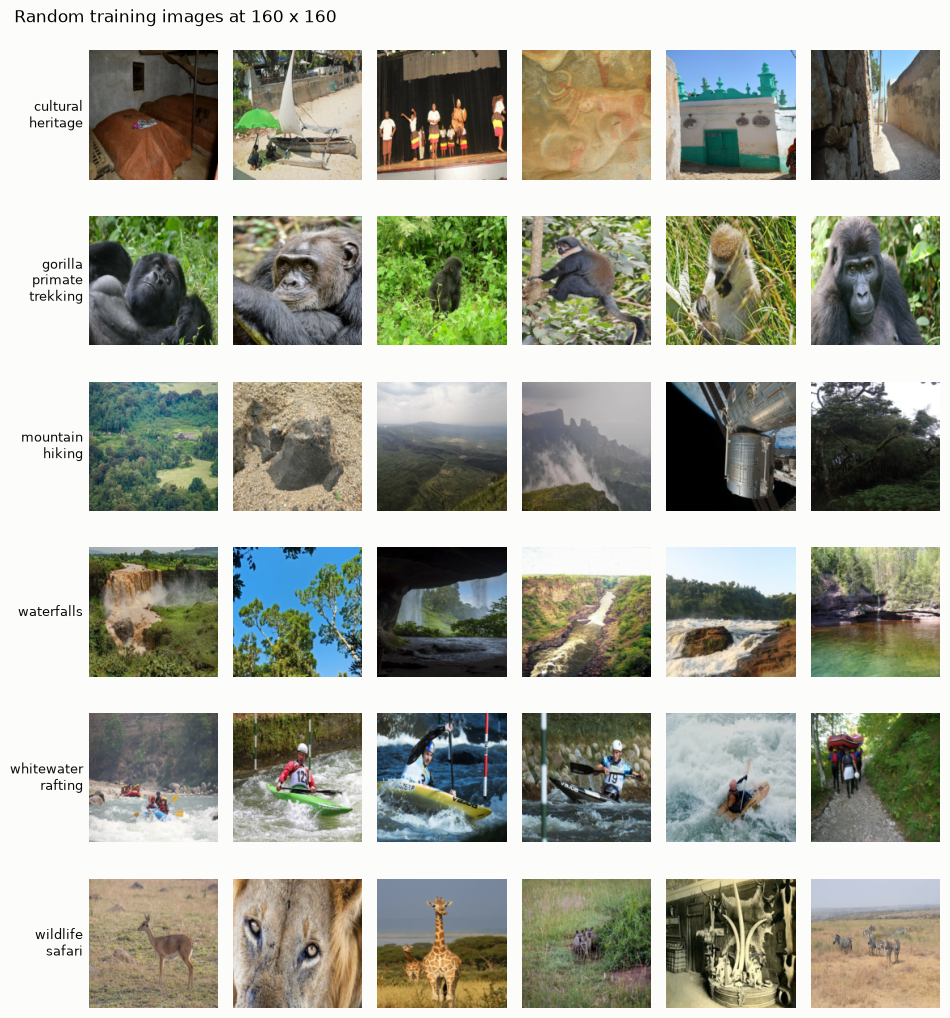

In [6]:
paths, path_labels = list_images(data_cfg.paths.processed_dir / "train", CLASSES)
paths, path_labels = np.array(paths), np.array(path_labels)
rng = np.random.default_rng(SEED)
per_row = 6
fig, axes = plt.subplots(len(CLASSES), per_row, figsize=(per_row * 1.6, len(CLASSES) * 1.75))
for row, name in enumerate(CLASSES):
    picks = rng.choice(paths[path_labels == row], per_row, replace=False)
    for col, path in enumerate(picks):
        ax = axes[row, col]
        ax.imshow(read_and_resize(tf.constant(path), model_cfg.image_size).numpy())
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        for spine in ax.spines.values():
            spine.set_visible(False)
    axes[row, 0].set_ylabel(name.replace("_", "\n"), rotation=0, ha="right", va="center", fontsize=9)
fig.suptitle(f"Random training images at {model_cfg.image_size} x {model_cfg.image_size}", x=0.02, ha="left")
plt.tight_layout()
plt.show()

## 7. Normalisation: work out the average colour of the training set
Normalising means: for each colour channel, subtract the average and divide by the spread (std).
Afterwards pixel values sit around 0 instead of 0-255, which helps the network train faster and more stably.
I use **training images only**: peeking at val/test would leak information about them.
The numbers are saved to `data/stats.json` so the app normalises uploaded photos exactly the same way.

In [7]:
mean, std, n = compute_channel_stats(raw_sets["train"])
save_stats(data_cfg.paths.stats_json, mean, std, model_cfg.image_size, n)
print(f"computed on {n} training images")
print("mean (R, G, B):", mean)
print("std  (R, G, B):", std)

computed on 12804 training images
mean (R, G, B): [119.6233, 120.1778, 105.2767]
std  (R, G, B): [64.1263, 62.6131, 68.622]


## 8. Chart: pixel values before and after normalisation
Left: how often each pixel value (0-255) appears in one batch, for red, green and blue.
Right: the same pixels after normalising, now centred on 0 with most values between about -2 and 2.
The shape doesn't change, only the scale moves; that's exactly what normalising should do.

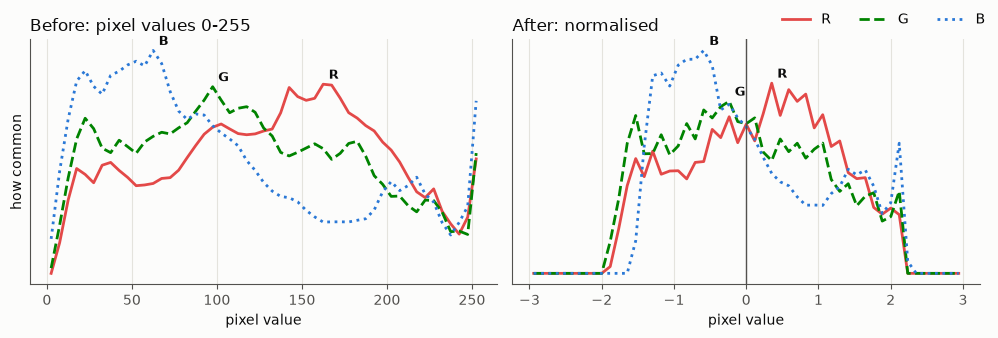

In [8]:
stats = load_stats(data_cfg.paths.stats_json)
norm_sets = load_datasets(data_cfg, model_cfg, train_cfg, stats=stats)
before, _ = next(iter(raw_sets["val"]))
after, _ = next(iter(norm_sets["val"]))            # same images: val is not shuffled

channels = [("R", "#e34948", "-"), ("G", "#008300", "--"), ("B", "#2a78d6", ":")]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, batch, bins, title in [(ax1, before, np.linspace(0, 255, 52), "Before: pixel values 0-255"),
                               (ax2, after, np.linspace(-3, 3, 52), "After: normalised")]:
    for c, (name, colour, style) in enumerate(channels):
        values = batch.numpy()[..., c].ravel()
        hist, edges = np.histogram(values, bins=bins, density=True)
        centres = (edges[:-1] + edges[1:]) / 2
        ax.plot(centres, hist, color=colour, linestyle=style, linewidth=2)
        peak = hist.argmax()
        ax.annotate(name, (centres[peak], hist[peak]), xytext=(4, 4), textcoords="offset points",
                    color="#0b0b0b", fontsize=9, fontweight="bold")
    ax.set_title(title, loc="left", color="#0b0b0b")
    ax.set_xlabel("pixel value")
    ax.set_yticks([])
ax1.set_ylabel("how common")
ax2.axvline(0, color="#52514e", linewidth=1)
fig.legend([plt.Line2D([], [], color=c, linestyle=s, linewidth=2) for _, c, s in channels],
           [n for n, _, _ in channels], ncol=3, frameon=False, loc="upper right")
plt.tight_layout()
plt.show()

## 9. Check: are the normalised values centred?
On the training set the mean should be almost exactly 0 and the std almost exactly 1, by construction.
Validation images were not used to compute the stats, so they land close to 0 and 1 but not exactly.
Close is good: it means val photos look like train photos, colour-wise.

In [9]:
def overall_mean_std(dataset):
    m, s, _ = compute_channel_stats(dataset)
    return np.round(m, 3), np.round(s, 3)

for split in ["train", "val"]:
    m, s = overall_mean_std(norm_sets[split])
    print(f"{split:5s} mean {m}  std {s}")

train mean [-0.  0.  0.]  std [1. 1. 1.]


val   mean [-0.019 -0.018  0.01 ]  std [0.997 0.999 0.991]


## 10. Augmentation: small random changes to training photos
Each epoch, every training photo gets randomly flipped left-right, tilted a little, zoomed, shifted,
and made brighter/darker. The model never sees the exact same picture twice, so it has to learn
the subject (a raft, a gorilla) instead of memorising pixels. I skip upside-down flips and colour
shifts, because skies are up and colour matters here (green forest, white water).

In [10]:
from pearlroute.preprocessing.augmentation import make_augment

print("settings:", train_cfg.augmentation.model_dump())
augment = make_augment(train_cfg.augmentation, seed=SEED)

settings: {'flip_horizontal': True, 'rotation': 0.04, 'zoom': 0.15, 'translation': 0.05, 'brightness': 0.1, 'contrast': 0.15, 'mix_prob': 0.6, 'mixup_alpha': 0.2, 'cutmix_alpha': 1.0}


## 11. Chart: one photo, many versions
The left column is the original photo; the other columns are what augmentation might produce from it.
Every version should still clearly show the same experience. If a change made the photo
unrecognisable (e.g. the raft cut off), the settings in `configs/train.yaml` would be too strong.

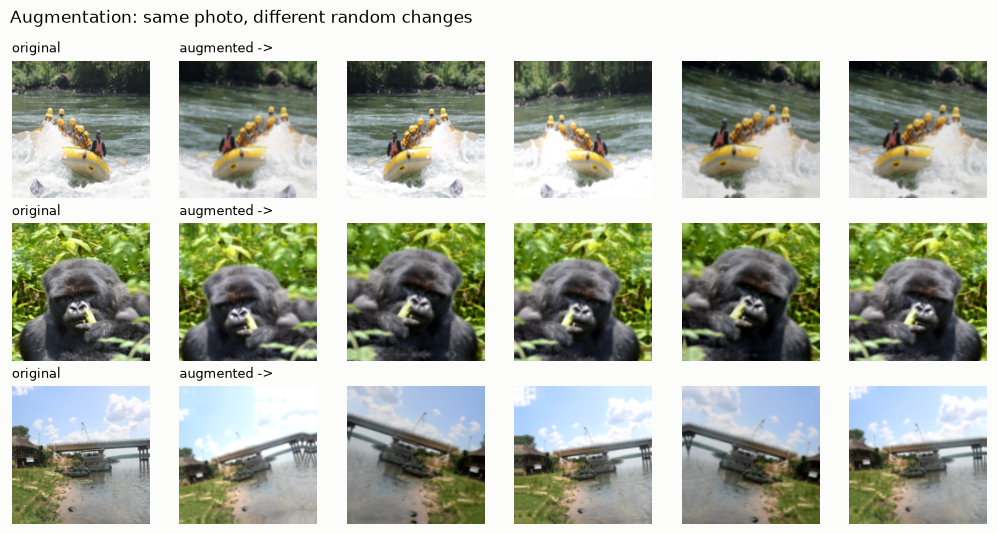

In [11]:
# Pick one training photo per class whose title names the subject, so the example is a clear one.
train_rows = splits[splits["split"] == "train"]
rng = np.random.default_rng(SEED)
examples = []
for name, word in [("whitewater_rafting", "raft"), ("gorilla_primate_trekking", "gorilla"), ("waterfalls", "falls")]:
    rows = train_rows[(train_rows["label"] == name) & train_rows["title"].str.contains(word, case=False)]
    examples.append(str(data_cfg.paths.raw_dir / rng.choice(rows["filename"].to_numpy())))
versions = 6
fig, axes = plt.subplots(len(examples), versions, figsize=(versions * 1.7, len(examples) * 1.8))
for row, path in enumerate(examples):
    original = tf.cast(read_and_resize(tf.constant(path), model_cfg.image_size), tf.float32)
    batch = tf.repeat(original[None], versions - 1, axis=0)        # 5 copies of the same photo
    shown = [original] + list(augment(batch))
    for col, img in enumerate(shown):
        ax = axes[row, col]
        ax.imshow(np.asarray(img).astype("uint8"))
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        for spine in ax.spines.values():
            spine.set_visible(False)
    axes[row, 0].set_title("original", fontsize=9, loc="left")
    axes[row, 1].set_title("augmented ->", fontsize=9, loc="left")
fig.suptitle("Augmentation: same photo, different random changes", x=0.02, ha="left")
plt.tight_layout()
plt.show()

## 12. The full training pipeline
This is exactly what the model will be fed: resize -> augment (train only) -> normalise.
Augmentation runs while the images are loaded, so it costs a little time each epoch but no disk space.
Validation and test images are never augmented: I want to score the model on real, unchanged photos.

In [12]:
import time

train_sets = load_datasets(data_cfg, model_cfg, train_cfg, augment=augment, stats=stats)
start = time.time()
batches = sum(1 for _ in train_sets["train"])
print(f"one training epoch of images: {batches} batches in {time.time() - start:.1f}s")
x, y = next(iter(train_sets["train"]))
print("train batch:", x.shape, "| mean", round(float(tf.reduce_mean(x)), 2), "| std", round(float(tf.math.reduce_std(x)), 2))
x_val, _ = next(iter(train_sets["val"]))
x_val_plain, _ = next(iter(norm_sets["val"]))
print("val batch unchanged by augmentation:", bool(np.allclose(x_val.numpy(), x_val_plain.numpy())))

one training epoch of images: 401 batches in 50.1s


train batch: (32, 160, 160, 3) | mean 0.06 | std 1.01


val batch unchanged by augmentation: True


## 13. Model A: the baseline CNN
A plain CNN: 4 blocks of *convolution* (small filters that detect edges, then textures, then shapes)
followed by *max-pooling* (shrinks the image by half, keeping the strongest signals).
Then one dense layer combines everything, dropout randomly switches off half its units to reduce
overfitting, and softmax turns the scores into 6 probabilities that add up to 1. This is the score to beat.

In [13]:
from pearlroute.models.registry import build_model

baseline = build_model("baseline", model_cfg, len(CLASSES))
baseline.summary()

Model: "baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 160, 160, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 80, 80, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 40, 40, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv4 (Conv2D)                  │ (None, 20, 20, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool4 (MaxPooling2D)            │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,638,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probabilities (Dense)           │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,880,134 (7.17 MB)

 Trainable params: 1,880,134 (7.17 MB)

 Non-trainable params: 0 (0.00 B)

## 14. Train the baseline (or load the saved one)
Training shows the model every training photo once per *epoch* and nudges its weights to reduce the loss.
Early stopping ends training when validation loss stops improving and keeps the best epoch's weights.
It takes about 1.5 hours on a CPU, so by default I load the model saved by `scripts/train.py`;
set `RETRAIN_BASELINE = True` to train it again here.

In [14]:
from pearlroute.models.io import load_model
from pearlroute.training.run import train_and_evaluate
from pearlroute.training.trainer import load_history

RETRAIN_BASELINE = False
baseline_dir = train_cfg.models_dir / "baseline"

if RETRAIN_BASELINE or not (baseline_dir / "model.keras").exists():
    result = train_and_evaluate("baseline", data_cfg, model_cfg, train_cfg)
    baseline = result["model"]
else:
    baseline, baseline_meta = load_model(baseline_dir)
baseline_history = load_history(baseline_dir)
baseline_metrics = json.loads((baseline_dir / "metrics.json").read_text())
print(f"trained {baseline_metrics['epochs_run']} epochs in {baseline_metrics['train_seconds'] / 60:.0f} min;"
      f" best epoch: {baseline_metrics['best_epoch']}")

trained 31 epochs in 87 min; best epoch: 19


## 15. Chart: learning curves
Blue is the training set, orange (dashed) is validation; the dotted line marks the best epoch.
If both curves improve together, the model is learning. If training keeps improving while validation
gets worse, the model is *overfitting*: memorising training photos instead of learning general patterns.

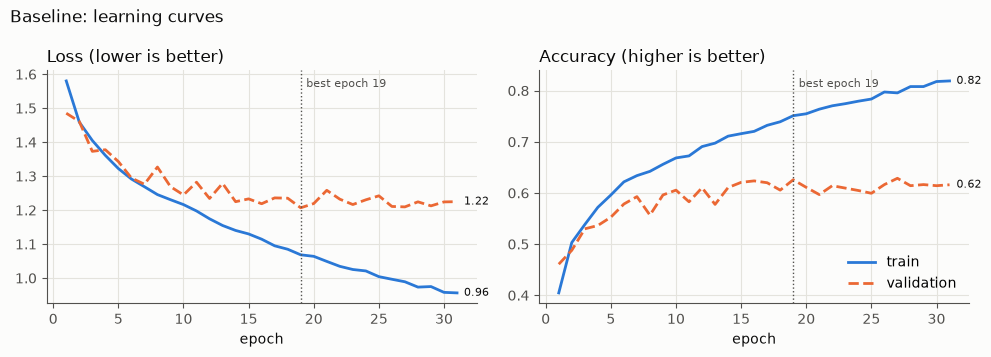

In [15]:
from pearlroute.evaluation.plots import plot_confusion_matrix, plot_history

plot_history(baseline_history, "Baseline: learning curves")
plt.show()

## 16. How good is the baseline? (test set)
The test set was never used for training or choosing the best epoch, so this is the fair score.
**Accuracy** = share of photos classified correctly. **Precision** = when it says "waterfalls", how often it's right;
**recall** = of all waterfall photos, how many it found; **F1** combines both. **ROC-AUC** (1.0 = perfect,
0.5 = guessing) checks how well the probabilities rank the right class above the wrong ones.

In [16]:
test_m = baseline_metrics["test"]
display(pd.DataFrame({name: [test_m[key]] for name, key in [
    ("accuracy", "accuracy"), ("precision (macro)", "precision_macro"), ("recall (macro)", "recall_macro"),
    ("F1 (macro)", "f1_macro"), ("ROC-AUC (macro)", "roc_auc_macro"), ("loss", "loss")]}, index=["baseline"]))
display(pd.DataFrame(test_m["per_class"]).T.sort_values("f1-score"))

,accuracy,precision (macro),recall (macro),F1 (macro),ROC-AUC (macro),loss
baseline,0.6259,0.6392,0.6214,0.6251,0.8831,1.0757


,precision,recall,f1-score,support
mountain_hiking,0.5412,0.5529,0.5470,463.0
gorilla_primate_trekking,0.6873,0.5415,0.6058,349.0
cultural_heritage,0.5313,0.7434,0.6197,491.0
wildlife_safari,0.6698,0.5837,0.6238,490.0
waterfalls,0.6764,0.6118,0.6425,492.0
whitewater_rafting,0.7291,0.6954,0.7118,476.0


## 17. Chart: confusion matrix
Each row is the true class, each column what the model predicted; the diagonal is correct answers.
Dark squares off the diagonal show which experiences the model mixes up, e.g. waterfalls vs rafting
(both white water) or mountains vs gorilla trekking (both green forest).

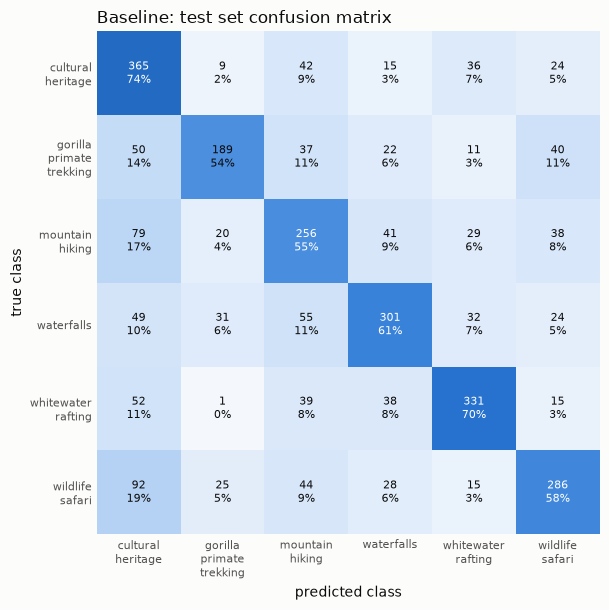

In [17]:
plot_confusion_matrix(test_m["confusion_matrix"], CLASSES, "Baseline: test set confusion matrix")
plt.show()

## 18. Look at some mistakes
Numbers don't tell me *why* the model is wrong, pictures do. These are test photos the baseline got wrong,
with the true class, the prediction and how confident it was. Some mistakes are the model's fault;
some are photos that were labelled wrongly when I collected them.

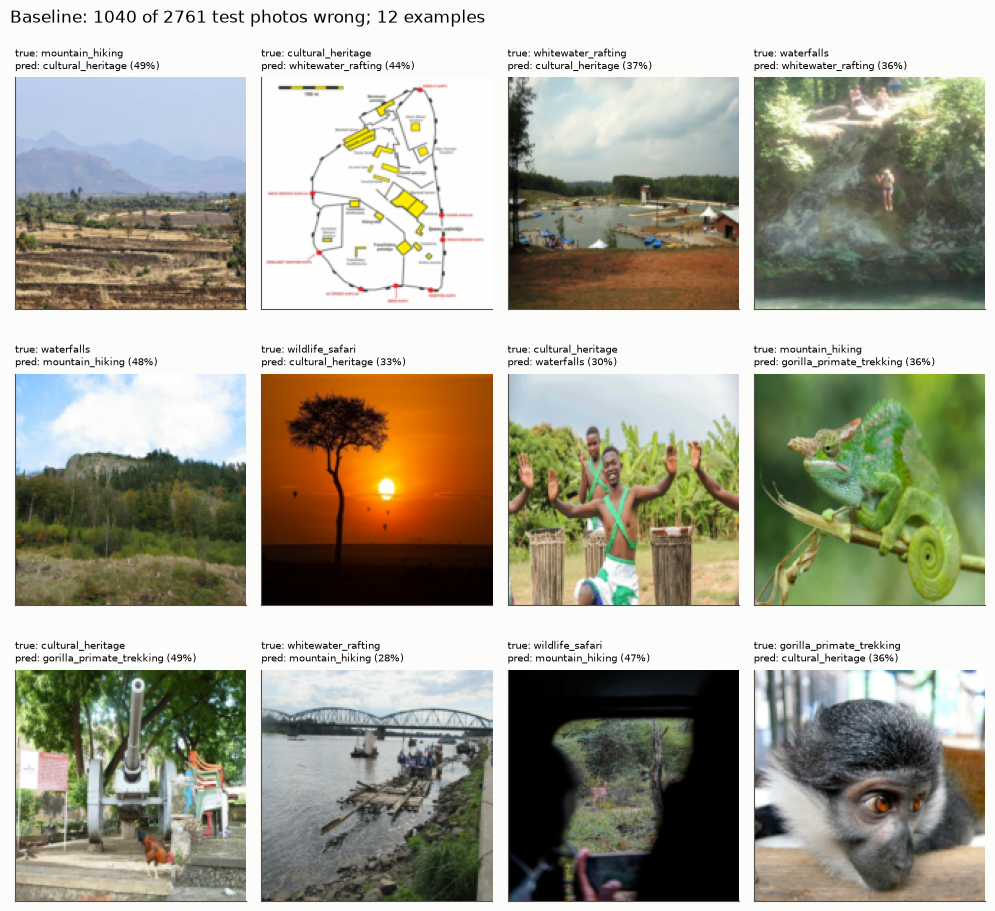

In [18]:
from pearlroute.evaluation.metrics import predict_dataset

test_paths, _ = list_images(data_cfg.paths.processed_dir / "test", CLASSES)
y_true, y_prob = predict_dataset(baseline, norm_sets["test"])          # same order as test_paths
y_pred = y_prob.argmax(axis=1)
wrong = np.flatnonzero(y_pred != y_true)
picks = np.random.default_rng(SEED).choice(wrong, min(12, len(wrong)), replace=False)
fig, axes = plt.subplots(3, 4, figsize=(10, 9.6))
for ax, i in zip(axes.ravel(), picks):
    ax.imshow(read_and_resize(tf.constant(test_paths[i]), model_cfg.image_size).numpy())
    ax.set_title(f"true: {CLASSES[y_true[i]]}\npred: {CLASSES[y_pred[i]]} ({y_prob[i].max():.0%})", fontsize=7.5, loc="left")
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.suptitle(f"Baseline: {len(wrong)} of {len(y_true)} test photos wrong; 12 examples", x=0.01, ha="left")
plt.tight_layout()
plt.show()

## 19. Model B: PearlNet
PearlNet fixes the baseline's weak spots. **Batch norm** after each convolution keeps training steady.
**Residual blocks** add a shortcut around each pair of convolutions, so a deeper network still trains well.
**Squeeze-excitation (SE)** lets each block turn useful channels up and others down for each photo.
**Global average pooling** replaces the baseline's huge Flatten + Dense layer (1.6 M weights in one layer).

In [19]:
pearlnet = build_model("pearlnet", model_cfg, len(CLASSES))
print(f"PearlNet: {pearlnet.count_params():,} parameters in {len(pearlnet.layers)} layers "
      f"(baseline: {baseline.count_params():,})")
pearlnet.summary(line_length=100, expand_nested=False, show_trainable=False)

PearlNet: 2,671,118 parameters in 73 layers (baseline: 1,880,134)


Model: "pearlnet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                ┃ Output Shape            ┃        Param # ┃ Connected to            ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)          │ (None, 160, 160, 3)     │              0 │ -                       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ stem1_conv (Conv2D)         │ (None, 80, 80, 32)      │            864 │ image[0][0]             │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ stem1_bn                    │ (None, 80, 80, 32)      │            128 │ stem1_conv[0][0]        │
│ (BatchNormalization)        │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ stem1_relu (ReLU)           │ (None, 80, 80, 32)      │              0 │ stem1_bn[0][0]          │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ stem2_conv (Conv2D)         │ (None, 80, 80, 32)      │          9,216 │ stem1_relu[0][0]        │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ stem2_bn                    │ (None, 80, 80, 32)      │            128 │ stem2_conv[0][0]        │
│ (BatchNormalization)        │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ stem2_relu (ReLU)           │ (None, 80, 80, 32)      │              0 │ stem2_bn[0][0]          │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ stage1_block1_a_conv        │ (None, 40, 40, 64)      │         18,432 │ stem2_relu[0][0]        │
│ (Conv2D)                    │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ stage1_block1_a_bn          │ (None, 40, 40, 64)      │            256 │ stage1_block1_a_conv[0… │
│ (BatchNormalization)        │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ stage1_block1_a_relu (ReLU) │ (None, 40, 40, 64)      │              0 │ stage1_block1_a_bn[0][… │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ stage1_block1_b_conv        │ (None, 40, 40, 64)      │         36,864 │ stage1_block1_a_relu[0… │
│ (Conv2D)                    │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ stage1_block1_b_bn          │ (None, 40, 40, 64)      │            256 │ stage1_block1_b_conv[0… │
│ (BatchNormalization)        │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ stage1_block1_se_squeeze    │ (None, 1, 1, 64)        │              0 │ stage1_block1_b_bn[0][… │
│ (GlobalAveragePooling2D)    │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ stage1_block1_se_reduce     │ (None, 1, 1, 8)         │            520 │ stage1_block1_se_squee… │
│ (Dense)                     │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ stage1_block1_se_expand     │ (None, 1, 1, 64)        │    

 Total params: 2,671,118 (10.19 MB)

 Trainable params: 2,666,382 (10.17 MB)

 Non-trainable params: 4,736 (18.50 KB)

## 20. Train PearlNet (or load the saved one)
Same data, same augmentation (including MixUp/CutMix) and same training settings as the baseline, so the comparison is fair.
PearlNet is deeper, so each epoch takes about 3x longer (~8 minutes on a CPU, about 5 hours in total).
By default I load `pearlnet_v4`, the version the app serves, saved by `scripts/train.py --model pearlnet --run-name pearlnet_v4`;
set `RETRAIN_PEARLNET = True` to retrain it here.

In [20]:
RETRAIN_PEARLNET = False
pearlnet_dir = train_cfg.models_dir / "pearlnet_v4"   # the model the app serves

if RETRAIN_PEARLNET or not (pearlnet_dir / "model.keras").exists():
    pearlnet = train_and_evaluate("pearlnet", data_cfg, model_cfg, train_cfg, run_name="pearlnet_v4")["model"]
else:
    pearlnet, pearlnet_meta = load_model(pearlnet_dir)
pearlnet_history = load_history(pearlnet_dir)
pearlnet_metrics = json.loads((pearlnet_dir / "metrics.json").read_text())
print(f"trained {pearlnet_metrics['epochs_run']} epochs in {pearlnet_metrics['train_seconds'] / 60:.0f} min;"
      f" best epoch: {pearlnet_metrics['best_epoch']}")

trained 39 epochs in 319 min; best epoch: 27


## 21. Chart: PearlNet learning curves
Compare this with section 15. Validation accuracy climbs higher than the baseline's (~0.67 vs ~0.61),
and the gap between training and validation is about the same (~0.13), so PearlNet learns more without memorising more.
Training accuracy looks low (~0.80) because it is measured on MixUp/CutMix images, which are harder than real photos.

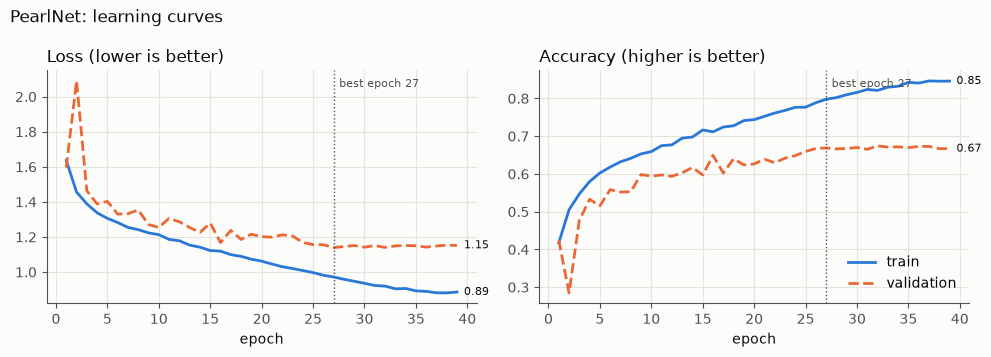

In [21]:
plot_history(pearlnet_history, "PearlNet: learning curves")
plt.show()

## 22. Baseline vs PearlNet on the test set
Both models are scored on the same 2,761 test photos that neither saw during training.
Higher is better for every column except loss. "Train-val gap" is training accuracy minus validation
accuracy at the best epoch: a big gap means overfitting.

In [22]:
def summary_row(metrics, history):
    t = metrics["test"]
    best = history.loc[metrics["best_epoch"]]
    return {"test accuracy": t["accuracy"], "F1 (macro)": t["f1_macro"], "precision (macro)": t["precision_macro"],
            "recall (macro)": t["recall_macro"], "ROC-AUC (macro)": t["roc_auc_macro"], "test loss": t["loss"],
            "train-val gap": round(best["accuracy"] - best["val_accuracy"], 3),
            "parameters": metrics["parameters"], "train minutes": round(metrics["train_seconds"] / 60, 1)}

comparison = pd.DataFrame({"baseline": summary_row(baseline_metrics, baseline_history),
                           "pearlnet": summary_row(pearlnet_metrics, pearlnet_history)}).T
display(comparison)

,test accuracy,F1 (macro),precision (macro),recall (macro),ROC-AUC (macro),test loss,train-val gap,parameters,train minutes
baseline,0.6259,0.6251,0.6392,0.6214,0.8831,1.0757,0.125,1880134.0,87.4
pearlnet,0.6592,0.6605,0.6798,0.6540,0.8964,1.0010,0.129,2671118.0,319.1


## 23. Chart: F1 score per class, baseline vs PearlNet
Each pair of bars is one class: blue = baseline, orange = PearlNet, longer is better.
This shows *where* PearlNet improved (or didn't), which the single accuracy number hides.

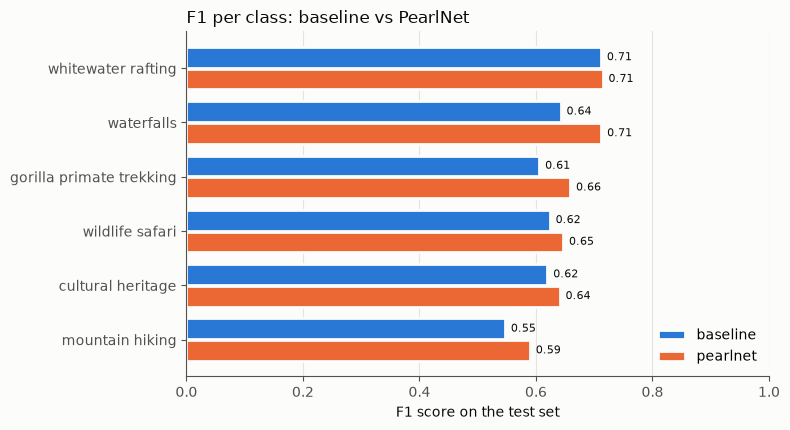

In [23]:
f1 = pd.DataFrame({name: {c: m["test"]["per_class"][c]["f1-score"] for c in CLASSES}
                   for name, m in [("baseline", baseline_metrics), ("pearlnet", pearlnet_metrics)]})
f1 = f1.sort_values("pearlnet")
fig, ax = plt.subplots(figsize=(8, 4.4))
y = np.arange(len(f1))
for offset, (name, colour) in zip([0.2, -0.2], [("baseline", "#2a78d6"), ("pearlnet", "#eb6834")]):
    ax.barh(y + offset, f1[name], height=0.38, color=colour, label=name, edgecolor="#fcfcfb", linewidth=2)
    for yi, v in zip(y + offset, f1[name]):
        ax.text(v + 0.01, yi, f"{v:.2f}", va="center", fontsize=8, color="#0b0b0b")
ax.set_yticks(y, [c.replace("_", " ") for c in f1.index])
ax.set_xlim(0, 1)
ax.set_xlabel("F1 score on the test set")
ax.grid(axis="y", visible=False)
ax.set_title("F1 per class: baseline vs PearlNet", loc="left", color="#0b0b0b")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

## 24. Chart: PearlNet confusion matrix
Same reading as section 17: the diagonal is correct, off-diagonal squares are mix-ups.
Compare it with the baseline's matrix to see which confusions PearlNet fixed and which remain.

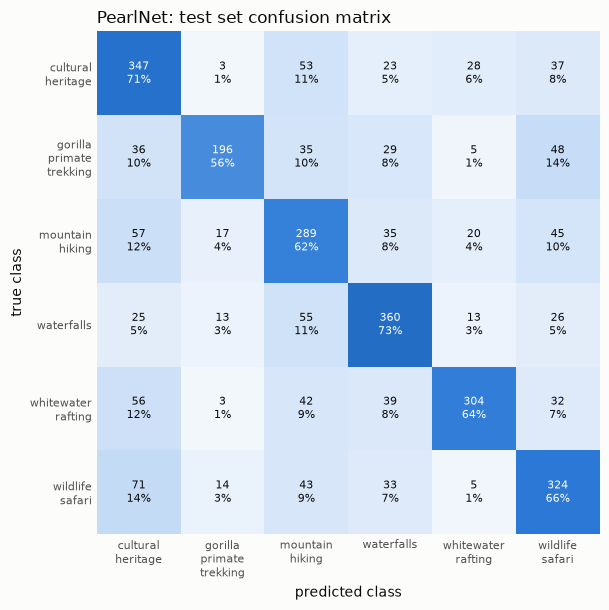

In [24]:
plot_confusion_matrix(pearlnet_metrics["test"]["confusion_matrix"], CLASSES, "PearlNet: test set confusion matrix")
plt.show()

## 25. Which model do I keep?
I pick the model with the higher **macro F1 on the validation set**, because it treats every class equally
(including gorilla_primate_trekking, the smallest class). I choose on validation, *not* test: if the test set helped
pick the model, its score would no longer be a fair, unseen check. The test score is reported afterwards.

In [25]:
val_f1 = {"baseline": baseline_metrics["val"]["f1_macro"], "pearlnet": pearlnet_metrics["val"]["f1_macro"]}
winner = max(val_f1, key=val_f1.get)
loser = next(name for name in val_f1 if name != winner)
print(f"Chosen on validation: {winner} (val macro F1 {val_f1[winner]:.3f} vs {val_f1[loser]:.3f} for {loser})")
print(f"Its fair test score: accuracy {comparison.loc[winner, 'test accuracy']:.1%}, "
      f"macro F1 {comparison.loc[winner, 'F1 (macro)']:.3f}")

Chosen on validation: pearlnet (val macro F1 0.674 vs 0.630 for baseline)
Its fair test score: accuracy 65.9%, macro F1 0.660


## 26. Trying to improve PearlNet
The first PearlNet on this dataset (v1) used Adam, an L2 penalty and a learning rate that drops when validation stalls.
For **v4** I changed only how it trains, not the network: **AdamW** (weight decay applied directly to the weights),
a **cosine** learning rate that warms up for 2 epochs and then slides smoothly down, and **MixUp/CutMix**
(blending two photos and their labels) on 60% of training batches. Val and test never changed.

In [26]:
from pearlroute.config import PROJECT_ROOT

runs = {"v1: Adam, plateau LR, L2": "models/pearlnet",
        "v4: AdamW, cosine LR, MixUp/CutMix (final)": "models/pearlnet_v4"}
rows = {}
for name, folder in runs.items():
    m = json.loads((PROJECT_ROOT / folder / "metrics.json").read_text())
    h = load_history(PROJECT_ROOT / folder)
    best = h.loc[m["best_epoch"]]
    rows[name] = {"val F1 (macro)": m["val"]["f1_macro"], "test accuracy": m["test"]["accuracy"],
                  "test F1 (macro)": m["test"]["f1_macro"], "test loss": m["test"]["loss"],
                  "train-val gap": round(best["accuracy"] - best["val_accuracy"], 3),
                  "epochs": m["epochs_run"], "train minutes": round(m["train_seconds"] / 60)}
display(pd.DataFrame(rows).T)

,val F1 (macro),test accuracy,test F1 (macro),test loss,train-val gap,epochs,train minutes
"v1: Adam, plateau LR, L2",0.6285,0.6342,0.6348,1.0448,0.151,26.0,136.0
"v4: AdamW, cosine LR, MixUp/CutMix (final)",0.6737,0.6592,0.6605,1.0010,0.129,39.0,319.0


## 27. Prediction: classify new photos
This is how the finished model is used on a photo it has never seen. I load the saved **`pearlnet_v4.h5`** file
and write `predict_image()`, which prepares the photo exactly as in training (resize to 160 x 160, normalise with
the training stats saved in the model's `metadata.json`) and returns the top 3 classes with their probabilities.
I try it on the 10 demo photos, which were held out of every split, so the model has never seen them.

In [27]:
import keras
from pearlroute.config import PROJECT_ROOT
from pearlroute.preprocessing.transforms import normalise

MODEL_DIR = PROJECT_ROOT / "models" / "pearlnet_v4"
model_h5 = keras.models.load_model(MODEL_DIR / "pearlnet_v4.h5", compile=False)
meta = json.loads((MODEL_DIR / "metadata.json").read_text())
MEAN, STD, SIZE = meta["normalisation"]["mean"], meta["normalisation"]["std"], meta["image_size"]


def predict_image(path, top_k=3):
    """Classify one photo: the same resize and normalisation as training, then the saved model."""
    image = tf.cast(read_and_resize(str(path), SIZE), tf.float32)
    x = normalise(tf.expand_dims(image, 0), MEAN, STD)
    probs = model_h5.predict(x, verbose=0)[0]
    order = np.argsort(probs)[::-1][:top_k]
    return [(meta["class_names"][i], round(float(probs[i]), 3)) for i in order]


demo_dir = PROJECT_ROOT / "data" / "demo"
demo = pd.read_csv(demo_dir / "demo_labels.csv")
predict_image(demo_dir / demo.loc[0, "file"])

[('gorilla_primate_trekking', 0.835),
 ('mountain_hiking', 0.052),
 ('waterfalls', 0.034)]

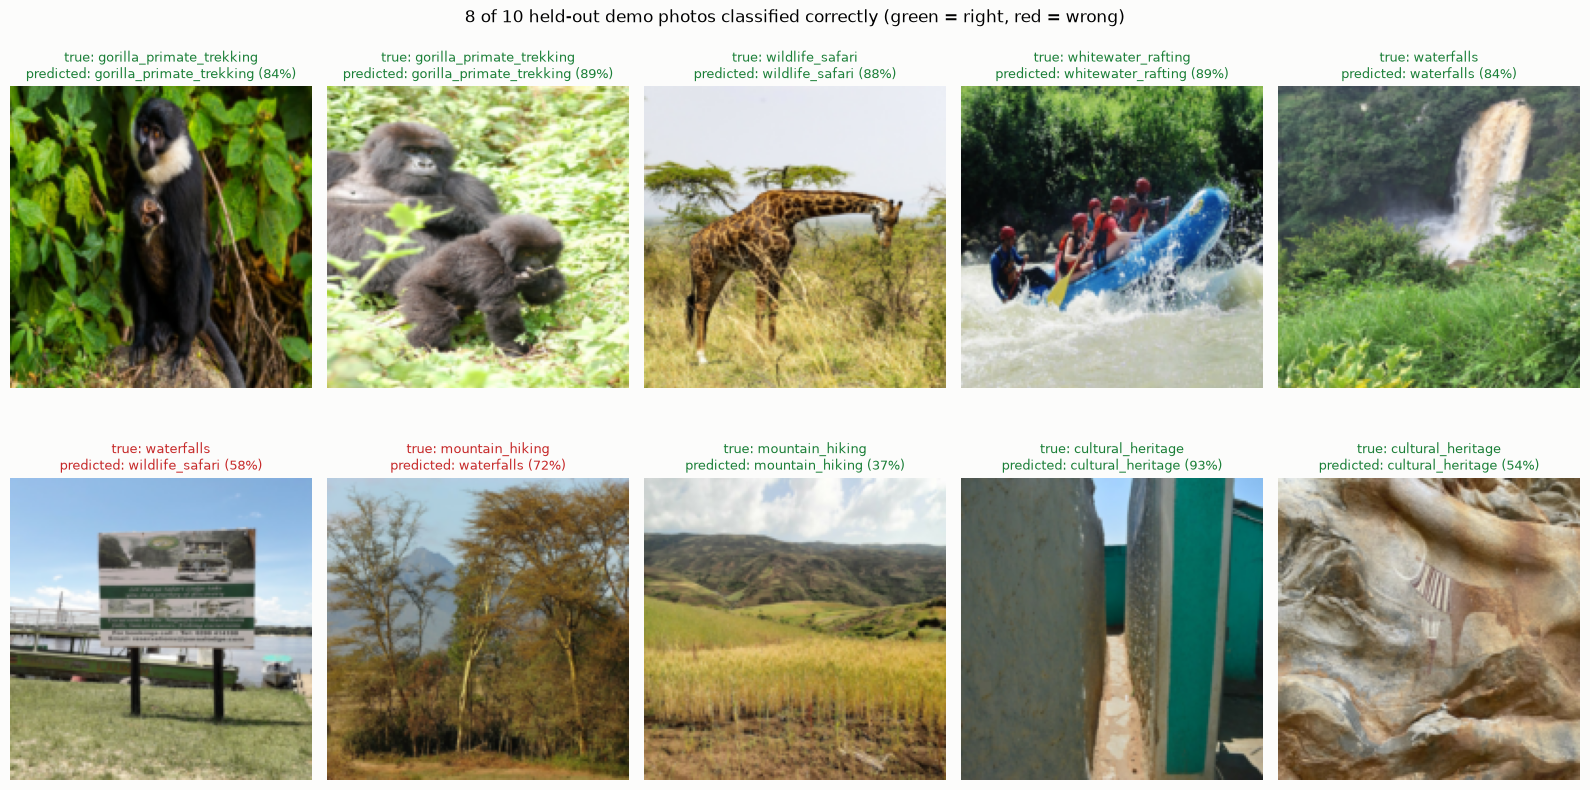

In [28]:
fig, axes = plt.subplots(2, 5, figsize=(16, 8.5))
correct = 0
for ax, (_, row) in zip(axes.flat, demo.iterrows()):
    (label, confidence), *_ = predict_image(demo_dir / row["file"])
    ok = label == row["label"]
    correct += ok
    ax.imshow(read_and_resize(str(demo_dir / row["file"]), SIZE).numpy().astype("uint8"))
    ax.set_title(f"true: {row['label']}\npredicted: {label} ({confidence:.0%})",
                 fontsize=9, color="#1a7f37" if ok else "#c62828")
    ax.axis("off")
fig.suptitle(f"{correct} of {len(demo)} held-out demo photos classified correctly (green = right, red = wrong)")
plt.tight_layout(h_pad=3)
plt.show()

The API and the Streamlit app do not call `predict_image()`; they use the `Predictor` class in
`src/pearlroute/inference/predictor.py`, which adds the destination suggestions and flags answers below 40% confidence
as uncertain. As a check, it gives the same answer as the notebook function for the first demo photo:

In [29]:
from pearlroute.inference.predictor import Predictor

predictor = Predictor()
first = demo_dir / demo.loc[0, "file"]
result = predictor.predict(str(first))
print("notebook function:", predict_image(first)[0])
print("API predictor:    ", (result.label, result.confidence), "uncertain:", result.uncertain)
print("destinations:     ", result.destinations[:3])

notebook function: ('gorilla_primate_trekking', 0.835)
API predictor:     ('gorilla_primate_trekking', 0.835) uncertain: False
destinations:      ['Bwindi (Uganda)', 'Mgahinga (Uganda)', 'Kibale (Uganda)']


## 28. What I learned
v4 beat v1 by about 2.5 points on test accuracy (65.9% vs 63.4%), with higher F1, lower loss and a smaller train-val gap.
With ~2,760 test photos the margin of error is about ±1.8 points, so a 2.5-point gain is unlikely to be noise. It cost more training time (39 epochs, ~5 hours vs ~2).
The biggest gain came from better training settings rather than a bigger network. I keep **v4**: it has the best validation F1,
and the app serves it. The limits now are labels (some photos fit two classes) and no "none of these" class.